A dense layer connects every input to every output. For a 100&times;100 image that is
10 000 inputs, so one hidden layer of 1 000 units needs **ten million weights** &mdash; and
having learned to recognise something in the top-left corner, it would have learned
nothing about the same thing in the bottom-right, because those are different weights
entirely.

A convolution fixes both problems with one idea: **use a small set of weights, and slide
it across the whole input.**

$$(\,I * K)[i,j] \;=\; \sum_{u}\sum_{v} I[i+u,\; j+v]\;K[u,v]$$

Two consequences follow, and they are the reason convolutional networks exist:

* **Parameter sharing** &mdash; the same 9 numbers are reused at every position, so cost stops
  scaling with input size.
* **Translation equivariance** &mdash; a pattern learned anywhere is detected everywhere,
  because it is literally the same detector being moved.

Everything below is worked out by hand on matrices small enough to print, then checked
against PyTorch.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
np.set_printoptions(precision=4, suppress=True, linewidth=140)


def banner(title, ch="="):
    print(ch * 78)
    print(f"  {title}")
    print(ch * 78)


def step(label):
    print()
    print(label)
    print("=" * 78)


def check(manual, from_array, label="MATCH"):
    ok = np.allclose(manual, from_array)
    print(f"      = {manual:+.6f}   |  from array: {from_array:+.6f}   |  {label}: {ok}")
    return ok


def expand(u, v, per_line=4):
    """Write a dot product out term by term."""
    terms = [f"({a:+.4f})*({b:+.4f})" for a, b in zip(u, v)]
    lines, out = [], ""
    for i, t in enumerate(terms):
        out += t + (" + " if i < len(terms) - 1 else "")
        if (i + 1) % per_line == 0:
            lines.append(out); out = ""
    if out:
        lines.append(out)
    return "\n      ".join(lines)


def show_matrix(M, name="M", rows=None, cols=None, fmt="{:+8.3f}", max_cols=14):
    M = np.asarray(M)
    if M.ndim == 1:
        M = M[None, :]
    cut = M.shape[1] > max_cols
    Ms = M[:, :max_cols] if cut else M
    print(f"{name} {np.asarray(M).shape}" +
          (f"   [first {max_cols} of {M.shape[1]} columns]" if cut else "") + " =")
    if cols is not None:
        head = "".join(f"{str(c):>10}" for c in (cols[:max_cols] if cut else cols))
        print(" " * 13 + head)
    for r in range(Ms.shape[0]):
        lab = f"{str(rows[r]):>10} | " if rows is not None else f"{r:>10} | "
        print("   " + lab + "  ".join(fmt.format(v) for v in Ms[r]))


def show_matmul(A, B, C, na="A", nb="B", nc="C", i=0, j=0,
                rows_A=None, note=None, max_cols=14):
    """Print both operands of A @ B = C, then verify one element by hand."""
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{na} {A.shape}   @   {nb} {B.shape}   =   {nc} {C.shape}")
    print(f"  shape rule: ({A.shape[0]} x {A.shape[1]}) @ ({B.shape[0]} x {B.shape[1]})"
          f" -> ({A.shape[0]} x {B.shape[1]})   inner dim {A.shape[1]} cancels")
    if note:
        print(f"  {note}")
    print("=" * 78)
    print()
    show_matrix(A, na, rows_A, max_cols=max_cols)
    print()
    show_matrix(B, nb, max_cols=max_cols)
    print()
    show_matrix(C, nc, rows_A, max_cols=max_cols)
    print(f"\n  worked element  {nc}[{i},{j}]  =  row {i} of {na}  .  column {j} of {nb}")
    print(f"      row {i} of {na} = {np.round(A[i], 4)}")
    print(f"      col {j} of {nb} = {np.round(B[:, j], 4)}")
    print(f"      {expand(A[i], B[:, j])}")
    check(float(A[i] @ B[:, j]), float(C[i, j]))


def show_elementwise(A, B, C, na, nb, nc, op="+", rows=None):
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{nc} = {na} {op} {nb}      all three are {A.shape} - element-wise")
    for r in range(A.shape[0]):
        lab = f"{rows[r]:>10}" if rows is not None else f"{r:>10}"
        print(f"\n{lab} |")
        print("   " + f"{na:>14}: " + "  ".join(f"{v:+8.3f}" for v in A[r]))
        print("   " + f"{nb:>14}: " + "  ".join(f"{v:+8.3f}" for v in B[r]))
        print("   " + f"{nc:>14}: " + "  ".join(f"{v:+8.3f}" for v in C[r]))
    print(f"\n  check [0,0]: {A[0,0]:+.6f} {op} {B[0,0]:+.6f} = {C[0,0]:+.6f}   "
          f"MATCH: {np.isclose(A[0,0] + B[0,0] if op == '+' else A[0,0] - B[0,0], C[0,0])}")


print("Display helpers ready: banner, step, check, expand, show_matrix, "
      "show_matmul, show_elementwise.")

Display helpers ready: banner, step, check, expand, show_matrix, show_matmul, show_elementwise.


---
# 1. Convolution, One Position at a Time

Start with a 6&times;6 input and a 3&times;3 kernel. The kernel is placed over the top-left
corner, the nine products are summed, and the result becomes one output pixel. Then the
kernel slides one step right and it happens again.

The input below has a **vertical edge**: values jump from 1 to 8 between columns 2 and 3.

In [2]:
I = np.array([
    [1, 1, 1, 8, 8, 8],
    [1, 1, 1, 8, 8, 8],
    [1, 1, 1, 8, 8, 8],
    [1, 1, 1, 8, 8, 8],
    [1, 1, 1, 8, 8, 8],
    [1, 1, 1, 8, 8, 8],
], dtype=float)

K = np.array([                 # a vertical-edge detector
    [ 1, 0, -1],
    [ 1, 0, -1],
    [ 1, 0, -1],
], dtype=float)

print("input I (6x6) - a bright region on the right, dark on the left\n")
show_matrix(I, "I", fmt="{:6.1f}")
print()
show_matrix(K, "kernel K (3x3)", fmt="{:6.1f}")

def conv2d(img, ker, stride=1, pad=0):
    if pad:
        img = np.pad(img, pad, mode="constant")
    kh, kw = ker.shape
    oh = (img.shape[0] - kh)//stride + 1
    ow = (img.shape[1] - kw)//stride + 1
    out = np.zeros((oh, ow))
    for r in range(oh):
        for c in range(ow):
            patch = img[r*stride:r*stride+kh, c*stride:c*stride+kw]
            out[r, c] = np.sum(patch * ker)
    return out

O = conv2d(I, K)
print(f"\noutput size: (6 - 3)/1 + 1 = {O.shape[0]} x {O.shape[1]}\n")
show_matrix(O, "output O", fmt="{:8.1f}")

print(f"\n\nposition (0,0) written out in full:\n")
patch = I[0:3, 0:3]
show_matrix(patch, "patch = I[0:3, 0:3]", fmt="{:6.1f}")
print()
terms = []
for u in range(3):
    for v in range(3):
        terms.append(f"({patch[u,v]:.0f})*({K[u,v]:+.0f})")
print("   O[0,0] = " + " + ".join(terms[:5]))
print("          + " + " + ".join(terms[5:]))
print(f"          = {np.sum(patch*K):.1f}")
print(f"   from the array: {O[0,0]:.1f}   MATCH: {np.isclose(np.sum(patch*K), O[0,0])}")
print(f"\n   The patch is uniform (all 1s), and the kernel's weights sum to zero,")
print(f"   so everything cancels. Flat regions produce nothing.")

print(f"\n\nposition (0,1) - now the patch straddles the edge:\n")
patch1 = I[0:3, 1:4]
show_matrix(patch1, "patch = I[0:3, 1:4]", fmt="{:6.1f}")
terms = [f"({patch1[u,v]:.0f})*({K[u,v]:+.0f})" for u in range(3) for v in range(3)]
print("\n   O[0,1] = " + " + ".join(terms[:5]))
print("          + " + " + ".join(terms[5:]))
print(f"          = {np.sum(patch1*K):.1f}")
print(f"\n   The left column sees 1s, the right column sees 8s, and the kernel")
print(f"   subtracts right from left: 3*(1) - 3*(8) = {3*1-3*8}. The edge is found.")

input I (6x6) - a bright region on the right, dark on the left

I (6, 6) =
            0 |    1.0     1.0     1.0     8.0     8.0     8.0
            1 |    1.0     1.0     1.0     8.0     8.0     8.0
            2 |    1.0     1.0     1.0     8.0     8.0     8.0
            3 |    1.0     1.0     1.0     8.0     8.0     8.0
            4 |    1.0     1.0     1.0     8.0     8.0     8.0
            5 |    1.0     1.0     1.0     8.0     8.0     8.0

kernel K (3x3) (3, 3) =
            0 |    1.0     0.0    -1.0
            1 |    1.0     0.0    -1.0
            2 |    1.0     0.0    -1.0

output size: (6 - 3)/1 + 1 = 4 x 4

output O (4, 4) =
            0 |      0.0     -21.0     -21.0       0.0
            1 |      0.0     -21.0     -21.0       0.0
            2 |      0.0     -21.0     -21.0       0.0
            3 |      0.0     -21.0     -21.0       0.0


position (0,0) written out in full:

patch = I[0:3, 0:3] (3, 3) =
            0 |    1.0     1.0     1.0
            1 |    1.0 

### The kernel *is* the feature detector

A convolution does not "look for edges" because someone wrote edge-detection code. It
computes a dot product between the kernel and each patch, so it responds most strongly to
patches that **look like the kernel**. Change the nine numbers and you change what the
layer detects.

In a trained network nobody chooses these numbers &mdash; they are learned by exactly the
gradient descent from the Neural Network walkthrough.

In [3]:
kernels = {
    "vertical edge":   np.array([[1,0,-1],[1,0,-1],[1,0,-1]], float),
    "horizontal edge": np.array([[1,1,1],[0,0,0],[-1,-1,-1]], float),
    "blur (average)":  np.ones((3,3))/9,
    "sharpen":         np.array([[0,-1,0],[-1,5,-1],[0,-1,0]], float),
    "identity":        np.array([[0,0,0],[0,1,0],[0,0,0]], float),
}

# an input with BOTH a vertical and a horizontal edge
J = np.ones((7,7))
J[:, 4:] = 8
J[4:, :] = 5

print("input J - a vertical edge at column 4 and a horizontal edge at row 4\n")
show_matrix(J, "J", fmt="{:5.1f}")

for name, ker in kernels.items():
    out = conv2d(J, ker)
    print(f"\n\n--- {name} ---   kernel sum = {ker.sum():.2f}")
    show_matrix(ker, "K", fmt="{:6.2f}")
    print()
    show_matrix(out, "output", fmt="{:7.2f}")

print(f"\n\nwhy the kernel SUM matters:")
print(f"   sums to 0  -> flat areas give 0; the kernel measures CHANGE (edges)")
print(f"   sums to 1  -> flat areas are preserved; the kernel measures INTENSITY")
print(f"\n   vertical edge kernel sums to {kernels['vertical edge'].sum():.0f}  -> "
      f"flat region output: {conv2d(np.ones((5,5)), kernels['vertical edge'])[0,0]:.1f}")
print(f"   blur kernel sums to {kernels['blur (average)'].sum():.0f}  -> "
      f"flat region output: {conv2d(np.ones((5,5)), kernels['blur (average)'])[0,0]:.1f}")

input J - a vertical edge at column 4 and a horizontal edge at row 4

J (7, 7) =
            0 |   1.0    1.0    1.0    1.0    8.0    8.0    8.0
            1 |   1.0    1.0    1.0    1.0    8.0    8.0    8.0
            2 |   1.0    1.0    1.0    1.0    8.0    8.0    8.0
            3 |   1.0    1.0    1.0    1.0    8.0    8.0    8.0
            4 |   5.0    5.0    5.0    5.0    5.0    5.0    5.0
            5 |   5.0    5.0    5.0    5.0    5.0    5.0    5.0
            6 |   5.0    5.0    5.0    5.0    5.0    5.0    5.0


--- vertical edge ---   kernel sum = 0.00
K (3, 3) =
            0 |   1.00    0.00   -1.00
            1 |   1.00    0.00   -1.00
            2 |   1.00    0.00   -1.00

output (5, 5) =
            0 |    0.00     0.00   -21.00   -21.00     0.00
            1 |    0.00     0.00   -21.00   -21.00     0.00
            2 |    0.00     0.00   -14.00   -14.00     0.00
            3 |    0.00     0.00    -7.00    -7.00     0.00
            4 |    0.00     0.00     0.00 

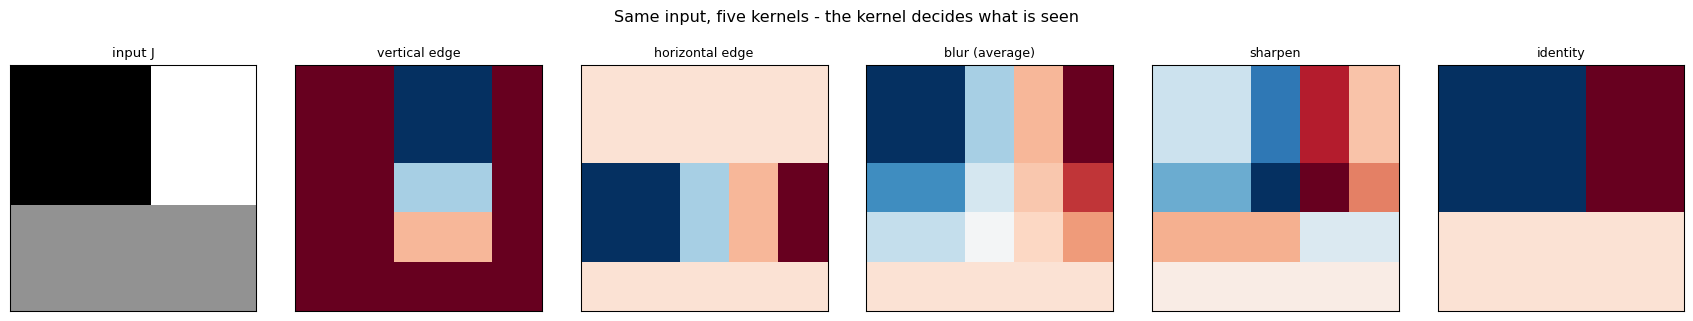

Blue and red are opposite signs. The vertical-edge kernel lights up only
along the vertical boundary, the horizontal one only along the horizontal
boundary, and the identity kernel reproduces the input unchanged.


In [4]:
fig, axes = plt.subplots(1, len(kernels)+1, figsize=(3.0*(len(kernels)+1), 3.2))
axes[0].imshow(J, cmap="gray"); axes[0].set_title("input J", fontsize=10)
axes[0].set_xticks([]); axes[0].set_yticks([])
for ax, (name, ker) in zip(axes[1:], kernels.items()):
    out = conv2d(J, ker)
    im = ax.imshow(out, cmap="RdBu_r")
    ax.set_title(name, fontsize=9.5); ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Same input, five kernels - the kernel decides what is seen", y=1.03)
plt.tight_layout(); plt.show()

print("Blue and red are opposite signs. The vertical-edge kernel lights up only")
print("along the vertical boundary, the horizontal one only along the horizontal")
print("boundary, and the identity kernel reproduces the input unchanged.")

---
# 2. Stride, Padding, and Output Size

Three settings control the output shape:

$$\text{out} = \left\lfloor \frac{\text{in} + 2p - k}{s} \right\rfloor + 1$$

* **kernel size $k$** &mdash; how much context each output sees
* **stride $s$** &mdash; how far the kernel jumps; $s = 2$ halves the resolution
* **padding $p$** &mdash; zeros added around the border

Padding exists because without it every convolution shrinks the input, and border pixels
are visited far less often than middle ones. `padding = (k-1)/2` keeps the size fixed &mdash;
"same" padding.

In [5]:
print(f"{'in':>4}  {'k':>3}  {'stride':>7}  {'pad':>4}  {'formula':>26}  {'out':>5}  "
      f"{'actual':>7}  {'match':>6}")
print("-" * 76)
for (sz, k, s, p) in [(6,3,1,0), (6,3,2,0), (6,3,1,1), (7,3,1,1), (7,3,2,1),
                      (8,5,1,0), (8,5,1,2), (8,3,3,0)]:
    img = np.arange(sz*sz, dtype=float).reshape(sz, sz)
    ker = np.ones((k,k))
    out = conv2d(img, ker, stride=s, pad=p)
    pred = (sz + 2*p - k)//s + 1
    f = f"({sz} + 2*{p} - {k})/{s} + 1"
    print(f"{sz:>4}  {k:>3}  {s:>7}  {p:>4}  {f:>26}  {pred:>5}  "
          f"{out.shape[0]:>7}  {str(out.shape[0]==pred):>6}")
print("-" * 76)

print(f"\n'same' padding keeps the size: for k = 3, p = 1; for k = 5, p = 2\n")
img5 = np.arange(25, dtype=float).reshape(5,5)
print(f"   input 5x5, k=3, p=0 -> {conv2d(img5, np.ones((3,3))).shape}   (shrunk)")
print(f"   input 5x5, k=3, p=1 -> {conv2d(img5, np.ones((3,3)), pad=1).shape}   (same)")

print(f"\n\nhow often is each pixel used, without padding? (3x3 kernel on 5x5)\n")
counts = np.zeros((5,5))
for r in range(3):
    for c in range(3):
        counts[r:r+3, c:c+3] += 1
show_matrix(counts, "times each input pixel is read", fmt="{:5.0f}")
print(f"\n   corner pixel: {counts[0,0]:.0f} time,  centre pixel: {counts[2,2]:.0f} times")
print(f"   Without padding the borders are systematically under-weighted.")

print(f"\n\nstride 2 - the kernel jumps two positions, halving resolution:\n")
big = np.arange(36, dtype=float).reshape(6,6)
show_matrix(big, "input 6x6", fmt="{:5.0f}")
print()
show_matrix(conv2d(big, kernels["identity"], stride=2), "identity kernel, stride 2",
            fmt="{:6.0f}")
print(f"\n   It kept rows/cols 1, 3 and skipped the rest - downsampling, and the")
print(f"   skipped information is simply gone.")

  in    k   stride   pad                     formula    out   actual   match
----------------------------------------------------------------------------
   6    3        1     0         (6 + 2*0 - 3)/1 + 1      4        4    True
   6    3        2     0         (6 + 2*0 - 3)/2 + 1      2        2    True
   6    3        1     1         (6 + 2*1 - 3)/1 + 1      6        6    True
   7    3        1     1         (7 + 2*1 - 3)/1 + 1      7        7    True
   7    3        2     1         (7 + 2*1 - 3)/2 + 1      4        4    True
   8    5        1     0         (8 + 2*0 - 5)/1 + 1      4        4    True
   8    5        1     2         (8 + 2*2 - 5)/1 + 1      8        8    True
   8    3        3     0         (8 + 2*0 - 3)/3 + 1      2        2    True
----------------------------------------------------------------------------

'same' padding keeps the size: for k = 3, p = 1; for k = 5, p = 2

   input 5x5, k=3, p=0 -> (3, 3)   (shrunk)
   input 5x5, k=3, p=1 -> (5, 5)   (same)

---
# 3. Channels and Filters

Real inputs have depth: an RGB image is 3 channels, a multi-channel EEG recording is one
channel per electrode. And one kernel detects only one pattern, so a layer uses many.

$$\text{one filter: } \;\; O[i,j] = \sum_{c=1}^{C_{in}}\sum_{u}\sum_{v} I[c,\,i+u,\,j+v]\;K[c,u,v] \;+\; b$$

Two things to get right:

* A filter spans **all input channels** and sums over them, producing **one** output map.
* A layer has $C_{out}$ such filters, so the weight tensor is
  $(C_{out}, C_{in}, k, k)$ and the output has $C_{out}$ channels.

In [6]:
C_IN, C_OUT, KS = 2, 3, 3
rng = np.random.default_rng(0)

X2 = np.stack([
    np.array([[1,1,1,6,6],[1,1,1,6,6],[1,1,1,6,6],[1,1,1,6,6],[1,1,1,6,6]], float),
    np.array([[2,2,2,2,2],[2,2,2,2,2],[9,9,9,9,9],[9,9,9,9,9],[9,9,9,9,9]], float),
])
W = rng.normal(0, .5, (C_OUT, C_IN, KS, KS))
b = rng.normal(0, .1, C_OUT)

print(f"input: {C_IN} channels of 5x5\n")
for c in range(C_IN):
    show_matrix(X2[c], f"channel {c}", fmt="{:5.1f}"); print()

def conv_multi(Xc, Wf, bf, stride=1, pad=0):
    Cout, Cin, kh, kw = Wf.shape
    if pad:
        Xc = np.pad(Xc, ((0,0),(pad,pad),(pad,pad)))
    oh = (Xc.shape[1]-kh)//stride + 1
    ow = (Xc.shape[2]-kw)//stride + 1
    out = np.zeros((Cout, oh, ow))
    for f in range(Cout):
        for r in range(oh):
            for cc in range(ow):
                patch = Xc[:, r*stride:r*stride+kh, cc*stride:cc*stride+kw]
                out[f, r, cc] = np.sum(patch * Wf[f]) + bf[f]
    return out

Y2 = conv_multi(X2, W, b)
print(f"weights W: {W.shape}  = (out_channels, in_channels, k, k)")
print(f"bias b   : {b.shape}")
print(f"output   : {Y2.shape}  = ({C_OUT} feature maps of "
      f"{Y2.shape[1]}x{Y2.shape[2]})\n")

print(f"filter 0, spanning both input channels:\n")
show_matrix(W[0,0], "W[0, channel 0]", fmt="{:+7.4f}"); print()
show_matrix(W[0,1], "W[0, channel 1]", fmt="{:+7.4f}")

print(f"\n\noutput[0, 0, 0] computed in full:\n")
p0, p1 = X2[0,0:3,0:3], X2[1,0:3,0:3]
s0 = np.sum(p0 * W[0,0]); s1 = np.sum(p1 * W[0,1])
print(f"   contribution from channel 0: sum(patch0 * W[0,0]) = {s0:+.6f}")
print(f"   contribution from channel 1: sum(patch1 * W[0,1]) = {s1:+.6f}")
print(f"   + bias b[0] = {b[0]:+.6f}")
print(f"   total = {s0:+.6f} {s1:+.6f} {b[0]:+.6f} = {s0+s1+b[0]:+.6f}")
print(f"   from the array: {Y2[0,0,0]:+.6f}   "
      f"MATCH: {np.isclose(s0+s1+b[0], Y2[0,0,0])}")

print(f"\n\nparameter count: {C_OUT} x {C_IN} x {KS} x {KS} + {C_OUT} = "
      f"{W.size + b.size}")
print(f"   and that number does NOT change if the input becomes 500x500.")

input: 2 channels of 5x5

channel 0 (5, 5) =
            0 |   1.0    1.0    1.0    6.0    6.0
            1 |   1.0    1.0    1.0    6.0    6.0
            2 |   1.0    1.0    1.0    6.0    6.0
            3 |   1.0    1.0    1.0    6.0    6.0
            4 |   1.0    1.0    1.0    6.0    6.0

channel 1 (5, 5) =
            0 |   2.0    2.0    2.0    2.0    2.0
            1 |   2.0    2.0    2.0    2.0    2.0
            2 |   9.0    9.0    9.0    9.0    9.0
            3 |   9.0    9.0    9.0    9.0    9.0
            4 |   9.0    9.0    9.0    9.0    9.0

weights W: (3, 2, 3, 3)  = (out_channels, in_channels, k, k)
bias b   : (3,)
output   : (3, 3, 3)  = (3 feature maps of 3x3)

filter 0, spanning both input channels:

W[0, channel 0] (3, 3) =
            0 | +0.0629  -0.0661  +0.3202
            1 | +0.0525  -0.2678  +0.1808
            2 | +0.6520  +0.4735  -0.3519

W[0, channel 1] (3, 3) =
            0 | -0.6327  -0.3116  +0.0207
            1 | -1.1625  -0.1094  -0.6230
      

### Parameter sharing, in numbers

This is the argument for convolution stated as a table. A dense layer's cost grows with
the *input size*; a convolution's does not.

In [7]:
print(f"{'input':>12}  {'dense -> 64 units':>20}  {'conv 3x3, 64 filters':>22}  {'ratio':>12}")
print("-" * 72)
for (h, w, c) in [(8,8,1), (28,28,1), (64,64,3), (128,128,3), (224,224,3), (512,512,3)]:
    dense = h*w*c * 64 + 64
    conv = 64 * c * 9 + 64
    print(f"{f'{h}x{w}x{c}':>12}  {dense:>20,}  {conv:>22,}  {dense/conv:>11,.0f}x")
print("-" * 72)
print("\nThe convolution column barely moves. At 512x512 a dense layer needs")
print(f"{(512*512*3*64+64)/(64*3*9+64):,.0f} times more parameters for the same 64 outputs.")
print("\nAnd parameters are not the only saving: fewer weights means less to")
print("estimate from data, which is regularisation in the sense of the")
print("Concepts walkthrough - lower variance, at the cost of assuming that")
print("local patterns are what matter.")

       input     dense -> 64 units    conv 3x3, 64 filters         ratio
------------------------------------------------------------------------
       8x8x1                 4,160                     640            6x
     28x28x1                50,240                     640           78x
     64x64x3               786,496                   1,792          439x
   128x128x3             3,145,792                   1,792        1,755x
   224x224x3             9,633,856                   1,792        5,376x
   512x512x3            50,331,712                   1,792       28,087x
------------------------------------------------------------------------

The convolution column barely moves. At 512x512 a dense layer needs
28,087 times more parameters for the same 64 outputs.

And parameters are not the only saving: fewer weights means less to
estimate from data, which is regularisation in the sense of the
Concepts walkthrough - lower variance, at the cost of assuming that
local patterns are 

---
# 4. Translation Equivariance

The claim: because the same kernel is applied everywhere, moving the input moves the
output by the same amount &mdash; the pattern does not have to be re-learned in each position.

$$\text{conv}(\text{shift}(I)) = \text{shift}(\text{conv}(I))$$

That is *equivariance* (the output moves with the input). Pooling then converts some of
it into *invariance* (the output stops caring where it was).

In [8]:
sig = np.zeros((7, 9))
sig[2:5, 1:4] = 5.0            # a small square, on the left
sig_shift = np.zeros((7, 9))
sig_shift[2:5, 5:8] = 5.0      # the SAME square, moved 4 columns right

det = np.array([[1,0,-1],[1,0,-1],[1,0,-1]], float)
o1, o2 = conv2d(sig, det), conv2d(sig_shift, det)

print("the same 3x3 square in two positions\n")
show_matrix(sig, "input A (square at cols 1-3)", fmt="{:4.0f}")
print()
show_matrix(o1, "conv(A)", fmt="{:6.0f}")
print()
show_matrix(sig_shift, "input B (square at cols 5-7)", fmt="{:4.0f}")
print()
show_matrix(o2, "conv(B)", fmt="{:6.0f}")

nz1 = np.nonzero(o1[0])[0] if o1[0].any() else np.nonzero(o1.any(axis=0))[0]
nz2 = np.nonzero(o2.any(axis=0))[0]
print(f"\nresponse columns in conv(A): {np.nonzero(o1.any(axis=0))[0].tolist()}")
print(f"response columns in conv(B): {nz2.tolist()}")
print(f"shift between them: {nz2.min() - np.nonzero(o1.any(axis=0))[0].min()} columns")
print(f"shift of the input: 4 columns")

rolled = np.roll(o1, 4, axis=1)
print(f"\nconv(shift(A)) equals shift(conv(A))? "
      f"{np.allclose(o2[:, 4:], o1[:, :-4])}")
print(f"\nThe SAME response pattern appears, just moved. A dense layer would have")
print(f"needed entirely separate weights to notice the square in position B.")

the same 3x3 square in two positions

input A (square at cols 1-3) (7, 9) =
            0 |    0     0     0     0     0     0     0     0     0
            1 |    0     0     0     0     0     0     0     0     0
            2 |    0     5     5     5     0     0     0     0     0
            3 |    0     5     5     5     0     0     0     0     0
            4 |    0     5     5     5     0     0     0     0     0
            5 |    0     0     0     0     0     0     0     0     0
            6 |    0     0     0     0     0     0     0     0     0

conv(A) (5, 7) =
            0 |     -5       0       5       5       0       0       0
            1 |    -10       0      10      10       0       0       0
            2 |    -15       0      15      15       0       0       0
            3 |    -10       0      10      10       0       0       0
            4 |     -5       0       5       5       0       0       0

input B (square at cols 5-7) (7, 9) =
            0 |    0     0   

---
# 5. Pooling

Pooling shrinks a feature map by summarising small neighbourhoods:

$$\text{max-pool}: \;\max_{(u,v)\in\text{window}} O[u,v]
\qquad\qquad
\text{avg-pool}: \;\frac{1}{|w|}\sum_{(u,v)\in\text{window}} O[u,v]$$

It has **no parameters**. It does three things: reduces computation, widens the
*receptive field* of later layers, and converts equivariance into a degree of
**invariance** &mdash; after max-pooling, a feature that moves by one pixel often produces the
identical output.

In [9]:
def pool(M, size=2, mode="max"):
    h, w = M.shape
    oh, ow = h//size, w//size
    out = np.zeros((oh, ow))
    for r in range(oh):
        for c in range(ow):
            win = M[r*size:(r+1)*size, c*size:(c+1)*size]
            out[r, c] = win.max() if mode == "max" else win.mean()
    return out

F = np.array([
    [1, 3, 2, 4],
    [5, 6, 1, 2],
    [7, 2, 9, 1],
    [1, 4, 3, 8],
], float)

print("feature map before pooling\n")
show_matrix(F, "F (4x4)", fmt="{:5.1f}")
print()
show_matrix(pool(F, 2, "max"), "max-pool 2x2", fmt="{:6.1f}")
print()
show_matrix(pool(F, 2, "avg"), "avg-pool 2x2", fmt="{:6.2f}")

print(f"\ntop-left window is [[{F[0,0]:.0f}, {F[0,1]:.0f}], [{F[1,0]:.0f}, {F[1,1]:.0f}]]")
print(f"   max  = {F[0:2,0:2].max():.1f}")
print(f"   mean = ({F[0,0]:.0f}+{F[0,1]:.0f}+{F[1,0]:.0f}+{F[1,1]:.0f})/4 = "
      f"{F[0:2,0:2].mean():.2f}")

print(f"\n\ninvariance: shift a feature by ONE pixel and re-pool\n")
G = np.zeros((4,4)); G[1,1] = 9.0
H = np.zeros((4,4)); H[1,0] = 9.0        # moved one column left, same 2x2 window
print(f"   feature at (1,1) -> max-pool: {pool(G).tolist()}")
print(f"   feature at (1,0) -> max-pool: {pool(H).tolist()}")
print(f"   identical? {np.array_equal(pool(G), pool(H))}")
Hb = np.zeros((4,4)); Hb[1,2] = 9.0      # moved ACROSS the window boundary
print(f"\n   feature at (1,2) -> max-pool: {pool(Hb).tolist()}")
print(f"   identical to (1,1)? {np.array_equal(pool(G), pool(Hb))}")
print(f"\n   So the invariance is LOCAL: movement within a pooling window is")
print(f"   absorbed, movement across a boundary is not. Stacking layers widens")
print(f"   the window and buys more of it.")

print(f"\n\nreceptive field - how much of the input one output value depends on:\n")
print(f"{'layer':>28}  {'receptive field':>16}")
print("-" * 48)
rf = 1
print(f"{'input pixel':>28}  {f'{rf}x{rf}':>16}")
for nm, k, s in [("conv 3x3", 3, 1), ("pool 2x2", 2, 2), ("conv 3x3", 3, 1),
                 ("pool 2x2", 2, 2), ("conv 3x3", 3, 1)]:
    rf = rf + (k-1) * (2 if "pool" in nm and rf > 1 else 1)
    rf = rf * s if s > 1 else rf
    print(f"{nm:>28}  {f'{rf}x{rf}':>16}")
print("-" * 48)
print("\nDepth is what lets a network built from 3x3 windows eventually 'see' a")
print("large object: each layer's window sits on top of the previous layer's.")

feature map before pooling

F (4x4) (4, 4) =
            0 |   1.0    3.0    2.0    4.0
            1 |   5.0    6.0    1.0    2.0
            2 |   7.0    2.0    9.0    1.0
            3 |   1.0    4.0    3.0    8.0

max-pool 2x2 (2, 2) =
            0 |    6.0     4.0
            1 |    7.0     9.0

avg-pool 2x2 (2, 2) =
            0 |   3.75    2.25
            1 |   3.50    5.25

top-left window is [[1, 3], [5, 6]]
   max  = 6.0
   mean = (1+3+5+6)/4 = 3.75


invariance: shift a feature by ONE pixel and re-pool

   feature at (1,1) -> max-pool: [[9.0, 0.0], [0.0, 0.0]]
   feature at (1,0) -> max-pool: [[9.0, 0.0], [0.0, 0.0]]
   identical? True

   feature at (1,2) -> max-pool: [[0.0, 9.0], [0.0, 0.0]]
   identical to (1,1)? False

   So the invariance is LOCAL: movement within a pooling window is
   absorbed, movement across a boundary is not. Stacking layers widens
   the window and buys more of it.


receptive field - how much of the input one output value depends on:

        

---
# 6. Backpropagation Through a Convolution

The gradient of a convolution is another convolution. Because a weight is **reused at
every position**, its gradient is the sum of its contributions everywhere:

$$\frac{\partial \mathcal{L}}{\partial K[u,v]} = \sum_{i,j}\frac{\partial \mathcal{L}}{\partial O[i,j]}\; I[i+u,\,j+v]$$

which is itself a correlation of the input with the output gradient. And the gradient
passed back to the input is a **full convolution with the flipped kernel**.

The summation is the important part: parameter sharing in the forward pass becomes
gradient *accumulation* in the backward pass. It is verified below against finite
differences.

In [10]:
Isml = np.array([[1., 2., 3., 0.],
                 [0., 1., 2., 3.],
                 [3., 0., 1., 2.],
                 [2., 3., 0., 1.]])
Ksml = np.array([[1., -1.],
                 [0.,  2.]])

def fwd_loss(img, ker):
    return float((conv2d(img, ker)**2).sum())      # simple scalar loss

Osml = conv2d(Isml, Ksml)
dL_dO = 2*Osml                                     # d/dO of sum(O^2)

# analytic gradient wrt the kernel
gK = np.zeros_like(Ksml)
for u in range(Ksml.shape[0]):
    for v in range(Ksml.shape[1]):
        gK[u, v] = np.sum(dL_dO * Isml[u:u+Osml.shape[0], v:v+Osml.shape[1]])

print("forward\n")
show_matrix(Isml, "I", fmt="{:5.1f}"); print()
show_matrix(Ksml, "K", fmt="{:5.1f}"); print()
show_matrix(Osml, "O = I * K", fmt="{:7.1f}")
print(f"\nloss = sum(O^2) = {fwd_loss(Isml, Ksml):.4f}")
print()
show_matrix(dL_dO, "dL/dO = 2*O", fmt="{:8.1f}")

print(f"\n\ndL/dK[0,0], summed over every position the weight was used:\n")
terms = []
for i in range(Osml.shape[0]):
    for j in range(Osml.shape[1]):
        terms.append(f"({dL_dO[i,j]:+.0f})*({Isml[i,j]:.0f})")
print("   " + " + ".join(terms))
print(f"   = {gK[0,0]:+.4f}")

EPSG = 1e-6
print(f"\n\ngradient check against central differences\n")
print(f"{'weight':>10}  {'analytic':>14}  {'numerical':>14}  {'rel err':>11}")
print("-" * 54)
worst = 0
for u in range(2):
    for v in range(2):
        orig = Ksml[u,v]
        Ksml[u,v] = orig + EPSG; lp = fwd_loss(Isml, Ksml)
        Ksml[u,v] = orig - EPSG; lm = fwd_loss(Isml, Ksml)
        Ksml[u,v] = orig
        num = (lp-lm)/(2*EPSG)
        rel = abs(gK[u,v]-num)/max(abs(gK[u,v])+abs(num), 1e-12)
        worst = max(worst, rel)
        print(f"{f'K[{u},{v}]':>10}  {gK[u,v]:>14.6f}  {num:>14.6f}  {rel:>11.2e}")
print("-" * 54)
print(f"\nworst relative error: {worst:.2e}   -> "
      f"{'CORRECT' if worst < 1e-6 else 'SUSPECT'}")

forward

I (4, 4) =
            0 |   1.0    2.0    3.0    0.0
            1 |   0.0    1.0    2.0    3.0
            2 |   3.0    0.0    1.0    2.0
            3 |   2.0    3.0    0.0    1.0

K (2, 2) =
            0 |   1.0   -1.0
            1 |   0.0    2.0

O = I * K (3, 3) =
            0 |     1.0      3.0      9.0
            1 |    -1.0      1.0      3.0
            2 |     9.0     -1.0      1.0

loss = sum(O^2) = 185.0000

dL/dO = 2*O (3, 3) =
            0 |      2.0       6.0      18.0
            1 |     -2.0       2.0       6.0
            2 |     18.0      -2.0       2.0


dL/dK[0,0], summed over every position the weight was used:

   (+2)*(1) + (+6)*(2) + (+18)*(3) + (-2)*(0) + (+2)*(1) + (+6)*(2) + (+18)*(3) + (-2)*(0) + (+2)*(1)
   = +138.0000


gradient check against central differences

    weight        analytic       numerical      rel err
------------------------------------------------------
    K[0,0]      138.000000      138.000000     7.81e-11
    K[0,1]    

---
# 7. Checking Against PyTorch

One detail catches people out: what deep-learning libraries call `Conv2d` is
mathematically a **cross-correlation**, not a convolution &mdash; the kernel is *not* flipped.
Since the kernel is learned, the distinction makes no practical difference, but it does
mean `scipy.signal.convolve2d` will disagree with `torch.nn.Conv2d` unless one of them is
flipped.

In [11]:
import torch
import torch.nn.functional as Fnn
from scipy.signal import convolve2d, correlate2d

t_in = torch.tensor(Isml, dtype=torch.float64)[None, None]
t_k = torch.tensor(np.array([[1., -1.], [0., 2.]]), dtype=torch.float64)[None, None]
t_out = Fnn.conv2d(t_in, t_k).numpy()[0, 0]

ours = conv2d(Isml, np.array([[1., -1.], [0., 2.]]))
sp_corr = correlate2d(Isml, np.array([[1., -1.], [0., 2.]]), mode="valid")
sp_conv = convolve2d(Isml, np.array([[1., -1.], [0., 2.]]), mode="valid")

print("ours vs torch vs scipy\n")
show_matrix(ours, "ours", fmt="{:8.2f}"); print()
show_matrix(t_out, "torch F.conv2d", fmt="{:8.2f}"); print()
show_matrix(sp_corr, "scipy correlate2d", fmt="{:8.2f}"); print()
show_matrix(sp_conv, "scipy convolve2d (flips!)", fmt="{:8.2f}")

print(f"\nours == torch              : {np.allclose(ours, t_out)}")
print(f"ours == scipy correlate2d  : {np.allclose(ours, sp_corr)}")
print(f"ours == scipy convolve2d   : {np.allclose(ours, sp_conv)}  "
      f"<- differs, because convolve2d flips the kernel")
print(f"flipped kernel matches it  : "
      f"{np.allclose(conv2d(Isml, np.flip(np.array([[1.,-1.],[0.,2.]]))), sp_conv)}")

print(f"\n\nmulti-channel layer against torch\n")
t_x = torch.tensor(X2, dtype=torch.float64)[None]
t_w = torch.tensor(W, dtype=torch.float64)
t_b = torch.tensor(b, dtype=torch.float64)
t_y = Fnn.conv2d(t_x, t_w, t_b).numpy()[0]
print(f"our output shape   : {Y2.shape}")
print(f"torch output shape : {t_y.shape}")
print(f"MATCH: {np.allclose(Y2, t_y)}")
print(f"max difference: {np.abs(Y2 - t_y).max():.3e}")

print(f"\n\nstride and padding against torch\n")
print(f"{'stride':>7}  {'pad':>4}  {'our shape':>12}  {'torch shape':>13}  {'match':>7}")
print("-" * 50)
for s in (1, 2):
    for p in (0, 1):
        o_ours = conv_multi(X2, W, b, stride=s, pad=p)
        o_t = Fnn.conv2d(t_x, t_w, t_b, stride=s, padding=p).numpy()[0]
        print(f"{s:>7}  {p:>4}  {str(o_ours.shape):>12}  {str(o_t.shape):>13}  "
              f"{str(np.allclose(o_ours, o_t)):>7}")
print("-" * 50)

print(f"\n\nmax-pooling against torch\n")
t_f = torch.tensor(F, dtype=torch.float64)[None, None]
tp = Fnn.max_pool2d(t_f, 2).numpy()[0, 0]
print(f"ours  : {pool(F, 2, 'max').tolist()}")
print(f"torch : {tp.tolist()}")
print(f"MATCH: {np.allclose(pool(F, 2, 'max'), tp)}")

print(f"\n\nbackward pass against torch autograd\n")
tk = torch.tensor(np.array([[1., -1.], [0., 2.]]), dtype=torch.float64,
                  requires_grad=True)
ti = torch.tensor(Isml, dtype=torch.float64)[None, None]
out_t = Fnn.conv2d(ti, tk[None, None])
loss_t = (out_t**2).sum()
loss_t.backward()
print(f"our dL/dK   :\n{np.round(gK, 6)}")
print(f"torch grad  :\n{np.round(tk.grad.numpy(), 6)}")
print(f"MATCH: {np.allclose(gK, tk.grad.numpy())}")

ours vs torch vs scipy

ours (3, 3) =
            0 |     1.00      3.00      9.00
            1 |    -1.00      1.00      3.00
            2 |     9.00     -1.00      1.00

torch F.conv2d (3, 3) =
            0 |     1.00      3.00      9.00
            1 |    -1.00      1.00      3.00
            2 |     9.00     -1.00      1.00

scipy correlate2d (3, 3) =
            0 |     1.00      3.00      9.00
            1 |    -1.00      1.00      3.00
            2 |     9.00     -1.00      1.00

scipy convolve2d (flips!) (3, 3) =
            0 |     3.00      5.00      7.00
            1 |    -3.00      3.00      5.00
            2 |     7.00     -3.00      3.00

ours == torch              : True
ours == scipy correlate2d  : True
ours == scipy convolve2d   : False  <- differs, because convolve2d flips the kernel
flipped kernel matches it  : True


multi-channel layer against torch

our output shape   : (3, 3, 3)
torch output shape : (3, 3, 3)
MATCH: True
max difference: 7.105e-15


stride 

---
# 8. A 1-D Convolution on EEG

Everything above generalises down a dimension, which is the form used for signals. A 1-D
kernel of length $k$ slides along time, and each filter learns a temporal motif &mdash; a
sharp transient, a rhythm, a particular slope.

This is the layer that appears at the bottom of most EEG models, including the ones fed
into the BERT-on-EEG walkthrough.

EEG: 64 samples at 64 Hz, with a burst at samples 28-40

          kernel                              values      sum                 detects
--------------------------------------------------------------------------------------
        smoother               [0.2 0.2 0.2 0.2 0.2]     1.00              slow trend
    edge / slope               [-1. -1.  0.  1.  1.]     0.00            rapid change
           spike          [-0.5 -1.   3.  -1.  -0.5]     0.00         sharp transient
--------------------------------------------------------------------------------------

position 30 of the spike detector, by hand:
   window  = [-0.3169 -0.2341 -0.     -0.0743 -0.6761]
   kernel  = [-0.5 -1.   3.  -1.  -0.5]
   (-0.3169)*(-0.5000) + (-0.2341)*(-1.0000) + (-0.0000)*(+3.0000) + (-0.0743)*(-1.0000) + 
      (-0.6761)*(-0.5000)
   = +0.804886
   from the array: +0.804886   MATCH: True


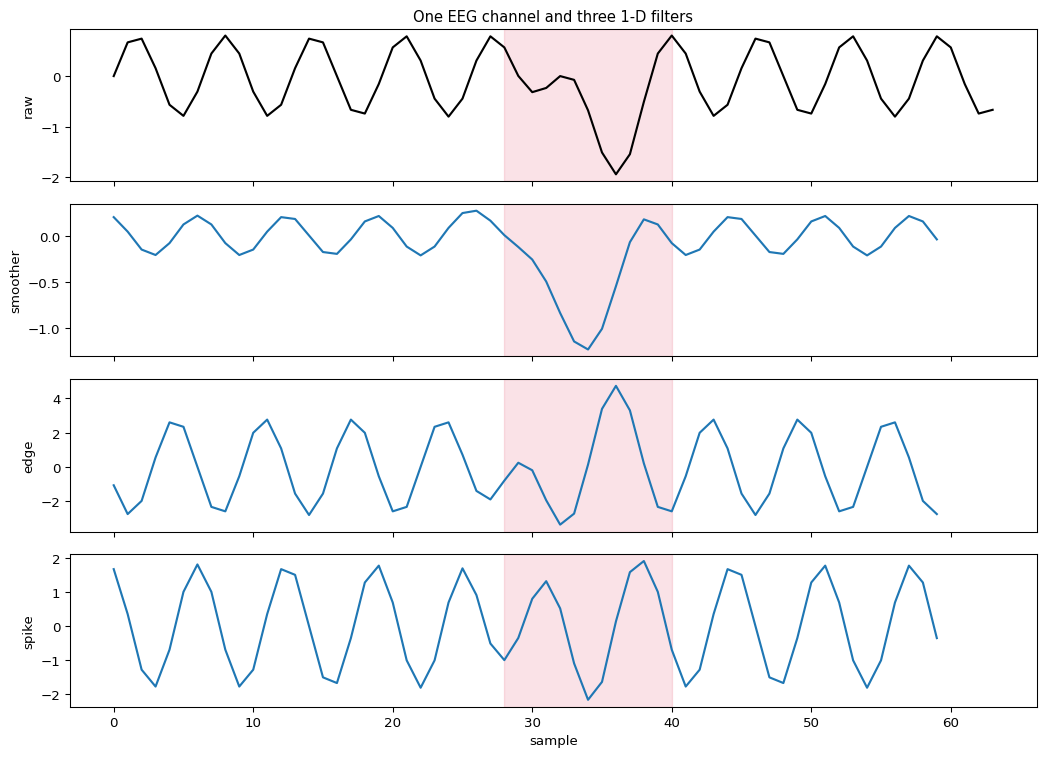


1-D convolution MATCH with torch: True

The spike filter is near zero through the alpha rhythm and jumps during
the burst. In a trained network these five numbers would not be chosen -
they would be learned, by exactly the gradient descent shown in section 6.


In [12]:
FS = 64
t = np.arange(0, 1, 1/FS)
eeg = 0.8*np.sin(2*np.pi*10*t)
burst = slice(28, 40)
eeg[burst] += 2.6*np.sin(2*np.pi*3*t[burst])*np.hanning(12)

k_smooth = np.ones(5)/5
k_edge = np.array([-1., -1., 0., 1., 1.])
k_spike = np.array([-0.5, -1., 3., -1., -0.5])

def conv1d(sigv, ker):
    L = len(sigv) - len(ker) + 1
    return np.array([np.sum(sigv[i:i+len(ker)]*ker) for i in range(L)])

print(f"EEG: {len(eeg)} samples at {FS} Hz, with a burst at samples "
      f"{burst.start}-{burst.stop}\n")
print(f"{'kernel':>16}  {'values':>34}  {'sum':>7}  {'detects':>22}")
print("-" * 86)
for nm, kk, what in [("smoother", k_smooth, "slow trend"),
                     ("edge / slope", k_edge, "rapid change"),
                     ("spike", k_spike, "sharp transient")]:
    print(f"{nm:>16}  {str(np.round(kk,2)):>34}  {kk.sum():>7.2f}  {what:>22}")
print("-" * 86)

print(f"\nposition 30 of the spike detector, by hand:")
w = eeg[30:35]
print(f"   window  = {np.round(w, 4)}")
print(f"   kernel  = {k_spike}")
print(f"   {expand(w, k_spike)}")
print(f"   = {float(np.sum(w*k_spike)):+.6f}")
print(f"   from the array: {conv1d(eeg, k_spike)[30]:+.6f}   "
      f"MATCH: {np.isclose(np.sum(w*k_spike), conv1d(eeg, k_spike)[30])}")

fig, axes = plt.subplots(4, 1, figsize=(11, 8), sharex=True)
axes[0].plot(eeg, lw=1.6, color="k"); axes[0].set_ylabel("raw")
axes[0].axvspan(burst.start, burst.stop, color="crimson", alpha=.12)
axes[0].set_title("One EEG channel and three 1-D filters", fontsize=11)
for ax, (nm, kk) in zip(axes[1:], [("smoother", k_smooth), ("edge", k_edge),
                                   ("spike", k_spike)]):
    ax.plot(conv1d(eeg, kk), lw=1.6)
    ax.axvspan(burst.start, burst.stop, color="crimson", alpha=.12)
    ax.set_ylabel(nm)
axes[-1].set_xlabel("sample")
plt.tight_layout(); plt.show()

t_sig = torch.tensor(eeg, dtype=torch.float64)[None, None]
t_ker = torch.tensor(k_spike, dtype=torch.float64)[None, None]
t_o = Fnn.conv1d(t_sig, t_ker).numpy()[0,0]
print(f"\n1-D convolution MATCH with torch: {np.allclose(conv1d(eeg, k_spike), t_o)}")
print(f"\nThe spike filter is near zero through the alpha rhythm and jumps during")
print(f"the burst. In a trained network these five numbers would not be chosen -")
print(f"they would be learned, by exactly the gradient descent shown in section 6.")

---
# 9. Summary

| Concept | Formula / rule |
|---|---|
| Convolution | $O[i,j] = \sum_{u,v} I[i+u,j+v]K[u,v]$ |
| Output size | $\lfloor (\text{in} + 2p - k)/s \rfloor + 1$ |
| "Same" padding | $p = (k-1)/2$ |
| Filter weights | $(C_{out}, C_{in}, k, k)$ &mdash; independent of input size |
| Parameters | $C_{out}\cdot C_{in}\cdot k^2 + C_{out}$ |
| Pooling | max or mean over a window; **no parameters** |
| Kernel gradient | $\partial\mathcal{L}/\partial K[u,v] = \sum_{i,j}\partial\mathcal{L}/\partial O[i,j]\cdot I[i+u,j+v]$ |
| Library convention | `Conv2d` is cross-correlation &mdash; no kernel flip |

**The one idea:** reuse a small set of weights at every position. That single decision
buys three things at once &mdash; a parameter count that does not grow with input size, a
detector that works anywhere in the input, and a strong prior that *what matters is local*.

**The prior is also the limitation.** A convolution assumes nearby values are related and
that the same pattern is meaningful everywhere. For images and signals that is true and
enormously helpful. For tabular data where column order is arbitrary it is false, which is
why convolutions are not used there and gradient-boosted trees are.

**What is deliberately left out:** dilated and transposed convolutions, 1&times;1 convolutions
as channel mixing, depthwise-separable convolutions, batch normalisation, residual
connections, and the architectures themselves (LeNet, ResNet, U-Net).